In [1]:
!nvidia-smi

Tue Oct 27 15:26:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
HOME = os.getcwd()
print("HOME:", HOME)

HOME: /content


Install Segment Anything Model (SAM) and other dependencies

In [3]:
!pip install -q 'git+https://github.com/facebookresearch/segment-anything.git'

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Install External Dependencies

In [4]:
!pip install -q jupyter_bbox_widget roboflow dataclasses-json supervision==0.23.0

Download SAM weights

In [5]:
!mkdir -p {HOME}/weights
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth -P {HOME}/weights

In [6]:
import os

CHECKPOINT_PATH = os.path.join(HOME, "weights", "sam_vit_h_4b8939.pth")
print(CHECKPOINT_PATH, "; exist:", os.path.isfile(CHECKPOINT_PATH))

/content/weights/sam_vit_h_4b8939.pth ; exist: True


default or vit_h: This denotes the ViT-H (Vision Transformer - Huge) SAM model. It is the largest of the three available models in terms of parameters and generally offers the highest accuracy.
* vit_l: This refers to the ViT-L (Vision Transformer - Large) SAM model.
* vit_b: This indicates the ViT-B (Vision Transformer - Base) SAM model, which is the smallest and fastest but may have slightly lower accuracy compared to the larger models.

In [7]:
import torch

DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
MODEL_TYPE = "vit_h"

* SamAutomaticMaskGenerator: This is a class that allows you to automatically generate segmentation masks for all objects in an image without requiring any specific prompts.
* SamPredictor: This is a class that enables you to get segmentation masks for specific objects in an image by providing prompts such as points, bounding boxes, or masks.

In [8]:
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor

sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT_PATH).to(device=DEVICE)

In [9]:
mask_generator = SamAutomaticMaskGenerator(sam)

In [10]:
import os
os.getcwd()

'/content'

In [11]:
IMAGE_NAME = "dogs_and_cow.jpg"
IMAGE_PATH = os.path.join(HOME,IMAGE_NAME)

In [12]:
import cv2
import supervision as sv

image_bgr = cv2.imread(IMAGE_PATH)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

sam_result = mask_generator.generate(image_rgb)

In [13]:
print(sam_result[0].keys())

dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])


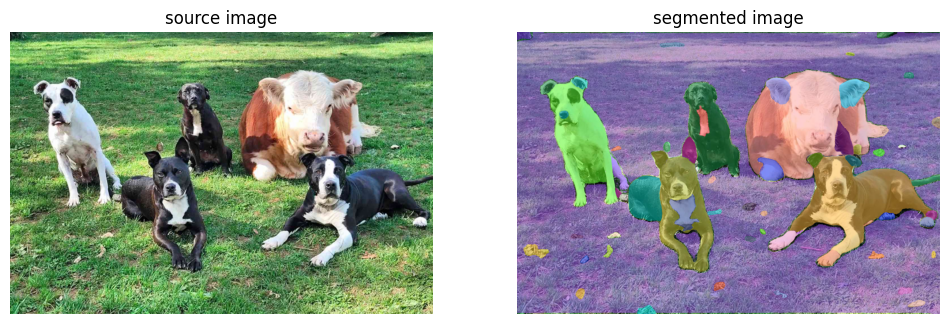

In [14]:
mask_annotator = sv.MaskAnnotator(color_lookup=sv.ColorLookup.INDEX)

detections = sv.Detections.from_sam(sam_result=sam_result)

annotated_image = mask_annotator.annotate(scene=image_bgr.copy(), detections=detections)

sv.plot_images_grid(
    images=[image_bgr, annotated_image],
    grid_size=(1, 2),
    titles=['source image', 'segmented image']
)

In [15]:
masks = [
    mask['segmentation']
    for mask
    in sorted(sam_result, key=lambda x: x['area'], reverse=True)
]

In [16]:
len(masks)

70

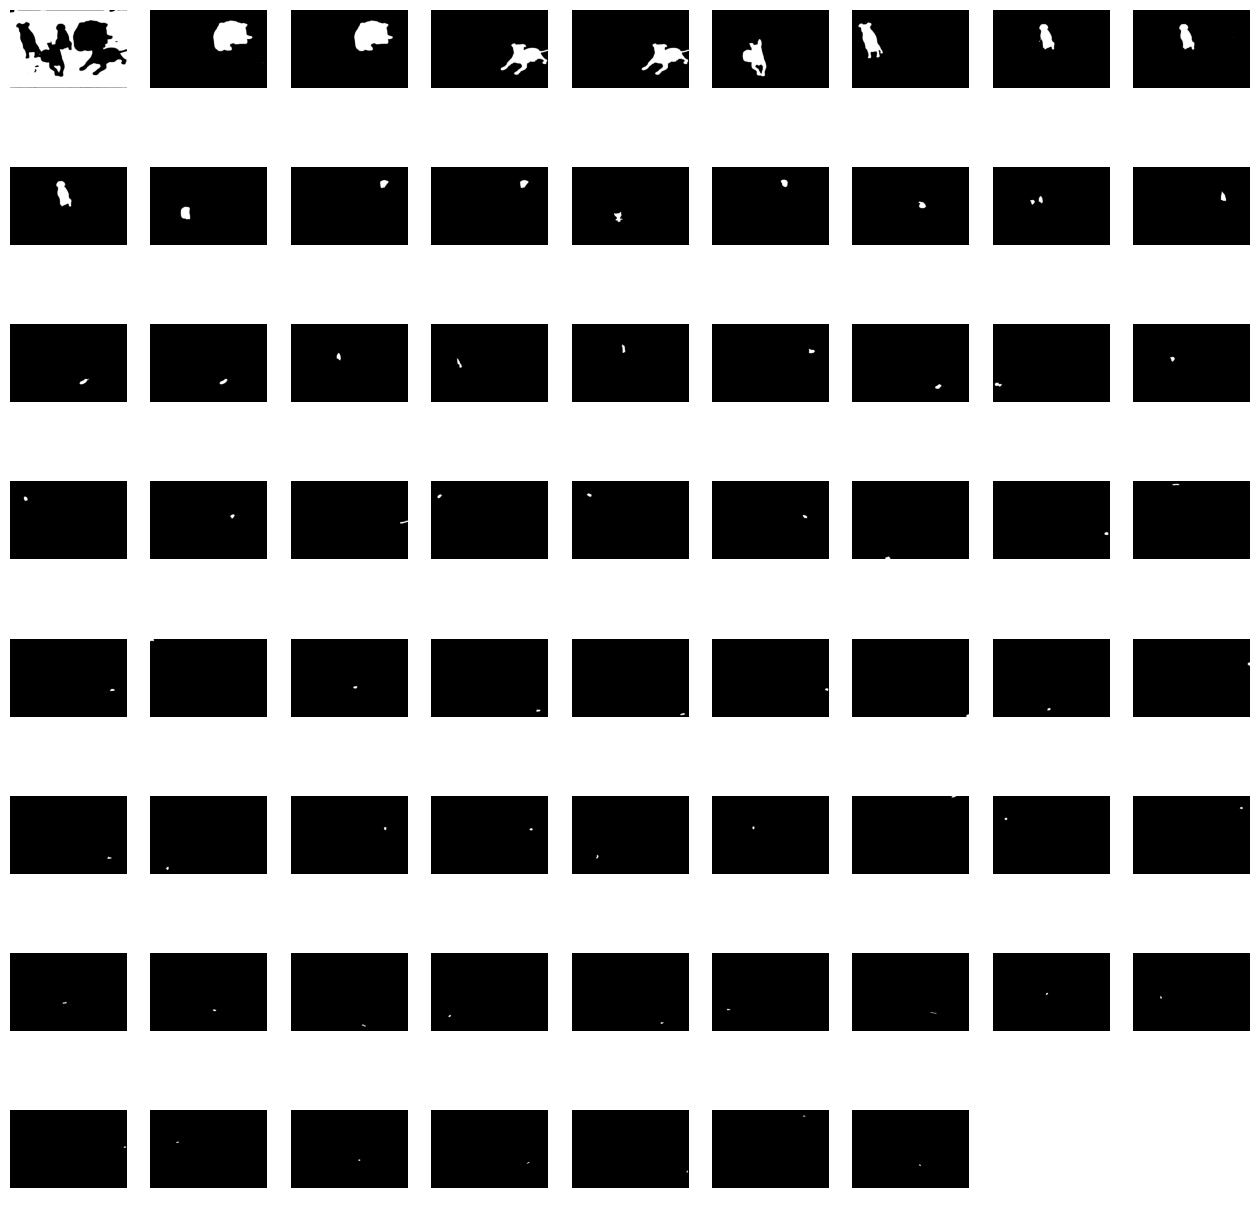

In [17]:
#sv.plot_images_grid(   images=masks,grid_size=(6, int(len(masks) / 8)),size=(16, 16))
#DON'T RUN THIS CELL WITHOUT CHEKING THE No of MASKS
import math

n = len(masks)
cols = math.ceil(math.sqrt(n))
rows = math.ceil(n / cols)

sv.plot_images_grid(
    images=masks,
    grid_size=(rows, cols),
    size=(16, 16)
)

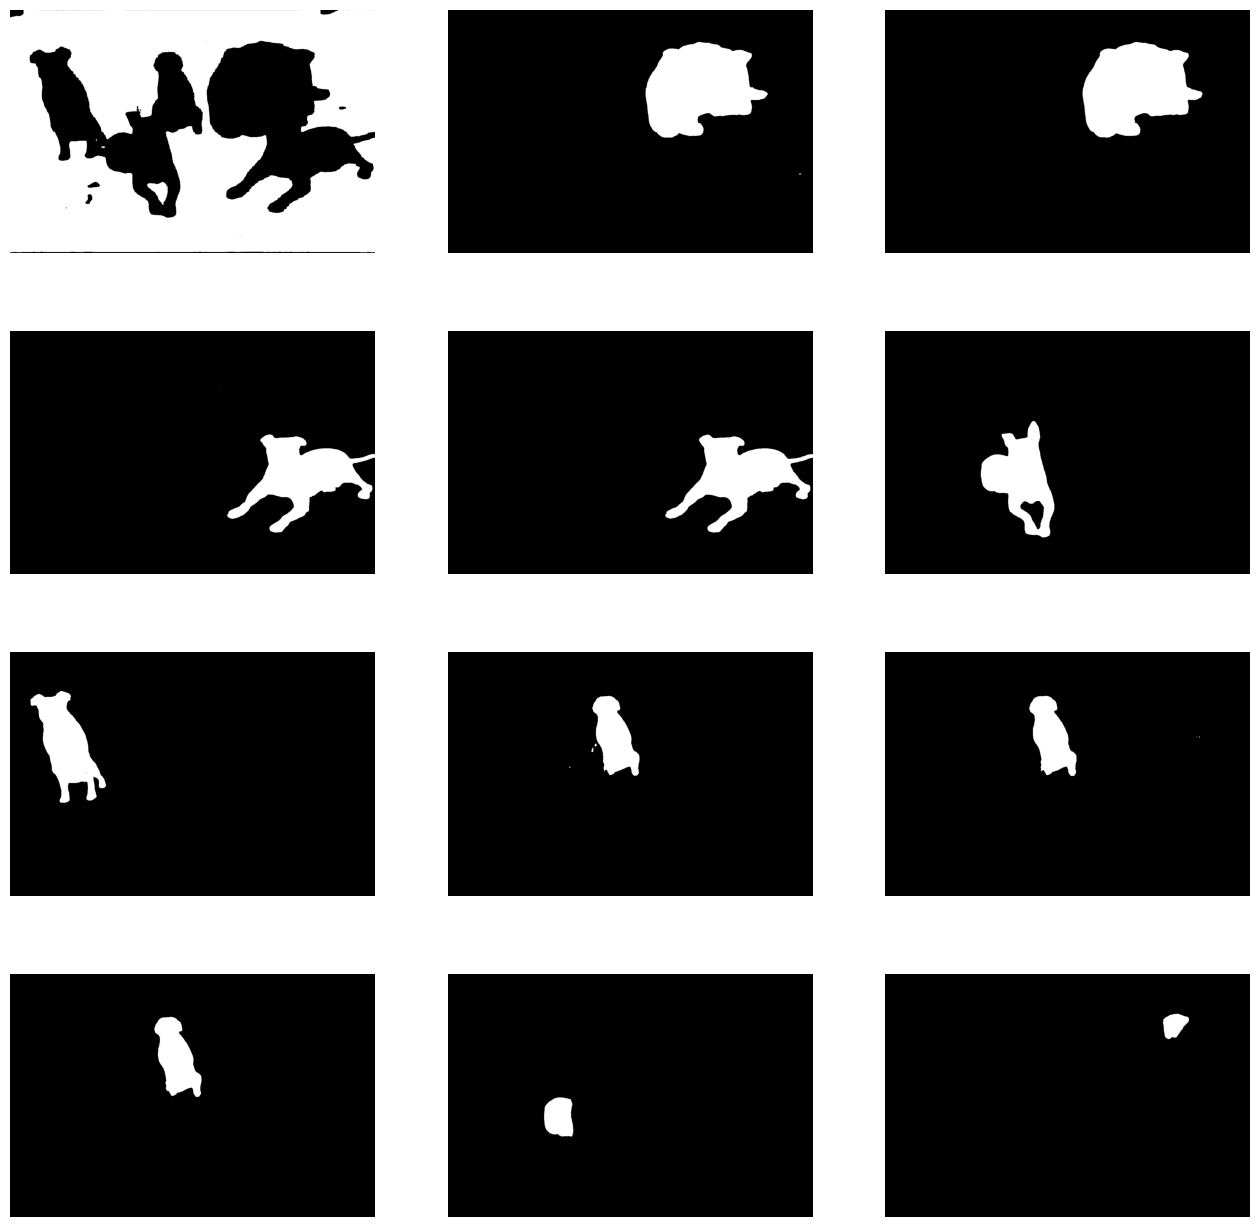

In [18]:
# Take top 40 masks
top_masks = masks[:12]

# Plot in an 8x5 grid
sv.plot_images_grid(
    images=top_masks,
    grid_size=(4, 3),  # 8 rows x 5 columns = 40 images
    size=(16, 16)
)

The SamPredictor class provides an easy interface to the model for prompting the model. It allows the user to first set an image using the set_image method, which calculates the necessary image embeddings. Then, prompts can be provided via the predict method to efficiently predict masks from those prompts. The model can take as input both point and box prompts, as well as masks from the previous iteration of prediction.

In [19]:
mask_predictor = SamPredictor(sam)

In [ ]:
#IMAGE_NAME = "dogs_and_cow.jpg"
#IMAGE_PATH = os.path.join(HOME,IMAGE_NAME)


Prepares it as a data URL that can be used directly in HTML (e.g., to display inside a widget or webpage).

In [20]:
# helper function that loads an image before adding it to the widget

import base64

def encode_image(filepath):
    with open(filepath, 'rb') as f:
        image_bytes = f.read()
    encoded = str(base64.b64encode(image_bytes), 'utf-8')
    return "data:image/jpg;base64,"+encoded

In [21]:
IS_COLAB = True

if IS_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

from jupyter_bbox_widget import BBoxWidget

widget = BBoxWidget()
widget.image = encode_image(IMAGE_PATH)
widget

In [22]:
widget.bboxes

[{'x': 797, 'y': 118, 'width': 560, 'height': 408, 'label': ''}]

In [23]:
import numpy as np

# Top left corner (x,y) of the bounding box along with width and height
default_box = {'x': 797, 'y': 118, 'width': 560, 'height': 408, 'label': ''}

box = widget.bboxes[0] if widget.bboxes else default_box
box = np.array([
    box['x'],
    box['y'],
    box['x'] + box['width'],
    box['y'] + box['height']
])

loading an image → converting to RGB → feeding it into a segmentation model → predicting masks within a user-defined box.

In [24]:
import cv2
import numpy as np
import supervision as sv

image_bgr = cv2.imread(IMAGE_PATH)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

mask_predictor.set_image(image_rgb)

masks, scores, logits = mask_predictor.predict(
    box=box,
    multimask_output=True
)

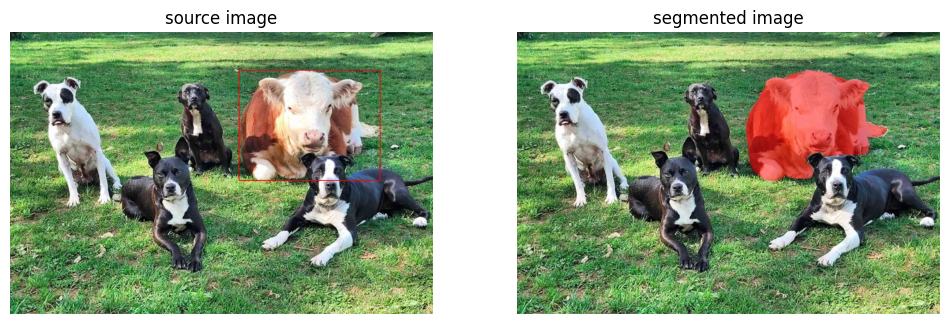

In [25]:
box_annotator = sv.BoxAnnotator(color=sv.Color.RED, color_lookup=sv.ColorLookup.INDEX) #color will be selected based on the index of each detection.
mask_annotator = sv.MaskAnnotator(color=sv.Color.RED, color_lookup=sv.ColorLookup.INDEX)
#Packs both masks and their bounding boxes into a Detections object.
detections = sv.Detections(
    xyxy=sv.mask_to_xyxy(masks=masks),
    mask=masks
)
detections = detections[detections.area == np.max(detections.area)] #Filters the detections to only keep the one with the largest area.

source_image = box_annotator.annotate(scene=image_bgr.copy(), detections=detections)
#Draws the segmentation mask (usually as a filled colored overlay) on a copy of the original image.
segmented_image = mask_annotator.annotate(scene=image_bgr.copy(), detections=detections)

sv.plot_images_grid(
    images=[source_image, segmented_image],
    grid_size=(1, 2),
    titles=['source image', 'segmented image']
)